# Week 9: Optimalizace a ortogonální polynomy

**Assignment:** [![Run in JupyterHub](https://img.shields.io/badge/Run%20in-JupyterHub-F37626?logo=jupyter)](https://hpc.troja.mff.cuni.cz:8000/hub/user-redirect/git-pull?app=lab&repo=https%3A%2F%2Fgitlab.karlin.mff.cuni.cz%2Fznm%2Fcviceni-student&branch=main&subpath=notebooks%2Fassignment%2Fweek-09-optimization-and-orthogonal-polynomials.ipynb) [![Download .ipynb](https://img.shields.io/badge/Download-.ipynb-blue)](https://gitlab.karlin.mff.cuni.cz/znm/cviceni-student/-/raw/main/notebooks/assignment/week-09-optimization-and-orthogonal-polynomials.ipynb?inline=false) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/num-math/cviceni-student/blob/main/notebooks/assignment/week-09-optimization-and-orthogonal-polynomials.ipynb)

**Solution:** [![Run in JupyterHub](https://img.shields.io/badge/Run%20in-JupyterHub-F37626?logo=jupyter)](https://hpc.troja.mff.cuni.cz:8000/hub/user-redirect/git-pull?app=lab&repo=https%3A%2F%2Fgitlab.karlin.mff.cuni.cz%2Fznm%2Fcviceni-student&branch=main&subpath=notebooks%2Fsolution%2Fweek-09-optimization-and-orthogonal-polynomials.ipynb) [![Download .ipynb](https://img.shields.io/badge/Download-.ipynb-blue)](https://gitlab.karlin.mff.cuni.cz/znm/cviceni-student/-/raw/main/notebooks/solution/week-09-optimization-and-orthogonal-polynomials.ipynb?inline=false) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/num-math/cviceni-student/blob/main/notebooks/solution/week-09-optimization-and-orthogonal-polynomials.ipynb)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import approx_fprime, minimize_scalar, curve_fit

## Část A: Optimalizace & Nelineární nejmenší čtverce

---
- [poznámky z přednášky - optimalizace 1](https://www.karlin.mff.cuni.cz/~kucera/ZNM/3%20-%20Optimalizace.pdf)
- [poznámky z přednášky - optimalizace 2](https://www.karlin.mff.cuni.cz/~kucera/ZNM/4%20-%20Ortogonalni%20polynomy.pdf)
- další materiály:
  - volně dostupná kniha [Nocedal, Wright: Numerical Optimization](https://www.math.uci.edu/~qnie/Publications/NumericalOptimization.pdf).
  - volně dostupná kniha [Madsen, Nielsen, Tingleff: Methods for Non-Linear Least Squares Problems](https://www2.imm.dtu.dk/pubdb/edoc/imm3215.pdf).
  - skripta [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (Volume 2, Kapitoly 12, 13, 14 a 15)

- ***Primární úlohy*** : A1, A2

- ***Úlohy k bonusové části zkoušky*** : -

- základní ***Learning outcomes*** (cviko, nikoliv přednáška)
  - Umím zařadit konkrétní optimalizační metody do jedné ze 3 základních kategorií (derivative-free, prvního stupně, druhého stupně).
  - Umím pojmenovat silné a slabé stránky 3 základních kategorií optimalizační metody (derivative-free, prvního stupně, druhého stupně).
---

### Intro

Dvě cvika zpátky jsme řešili lineární problém nejmenších čtverců, kde jsme hledali řešení

\begin{equation*}
\min\limits_{\mathbf{x} \in \mathbb{R}^n} \, \frac{1}{2} \left\| \mathbf{b} - A \mathbf{x} \right\|_2^2
\quad \left( \equiv \quad
\min\limits_{\mathbf{x} \in \mathbb{R}^n} \, \left\| \mathbf{b} - A \mathbf{x} \right\|_2 \right).
\end{equation*}

Jak jsme naznačovali/odkazovali už tam, tak *lineární* problém nejmenších čtverců je pouze speciální případ obecného problému nejmenších čtverců, kde pro danou funkci $\mathbf{F}\, :\, \mathbb{R}^{n}\rightarrow \mathbb{R}^{m}$ chceme řešit

\begin{equation*}
\min\limits_{\mathbf{x} \in \mathbb{R}^n} \, \frac{1}{2} \left\| \mathbf{F}( \mathbf{x} )\right\|_2^2
\quad \left( \equiv \quad
\min\limits_{\mathbf{x} \in \mathbb{R}^n} \, \left\| \mathbf{F}( \mathbf{x} ) \right\|_2 \right).
\end{equation*}

Mnoho, ne-li většina aplikací, ze kterých tyto problémy pramení souvisí s MLE principem;  více detailů a cool příklady lze najít v (českém) článku [200 let metody nejmenších čtverců](https://eudml.org/doc/196517) nebo třeba v knize [Hřebíček, Gander: Solving Problems in Scientific Computing using Maple and MATLAB](https://math.haifa.ac.il/ROVENSKI/rovenski/Proj.pdf).

Nicméně i toto je pouze relativně úzká podmnožina *optimalizačních problémů*, které se pro danou funkci $f\, : \, \mathbb{R}^{n} \rightarrow \mathbb{R}$ snaží najít

\begin{equation*}
\min\limits_{\mathbf{x} \, \in \,  \mathcal{C}} \, f( \mathbf{x} ),
\end{equation*}

kde $\mathcal{C} \subset \mathbb{R}^{n}$ je daná množina, na které chceme minimalizovat $f$ ("$\mathcal{C}$" jako *constraint set*). My se níže podíváme pouze na případ $C=\mathbb{R}^{n}$, tj. žádná omezení si klást nebudeme. To je v mnoha případech nerealistické, ale postupy pro $\mathcal{C} \neq \mathbb{R}^{n}$ jdou nad rámec základního kurzu - více se můžete naučit v předmětech [Numerická optimalizace 1](https://is.cuni.cz/studium/predmety/index.php?id=cb4f3efaaec13b50e61406ca19460e4d&tid=&do=predmet&kod=NMNV503) a [Numerická optimalizace 2](https://is.cuni.cz/studium/predmety/index.php?id=cb4f3efaaec13b50e61406ca19460e4d&tid=&do=predmet&kod=NMNV544&skr=2024&fak=11320).

Na přednášce jsme viděli celkem tři kategorie *iterativních* metod (jiné se prakticky využívají spíše ojediněle)
  - **derivative-free** - založeno pouze na vyhodnocování $f$,
    - [bisekce](https://en.wikipedia.org/wiki/Bisection_method), [metoda zlatého řezu](https://en.wikipedia.org/wiki/Golden-section_search), [**Nelder-Mead**](https://en.wikipedia.org/wiki/Nelder%E2%80%93Mead_method)
  - **first order** - založeno na vyhodnocování $f$ a jejího gradientu $\nabla f$,
    - [metoda největšího spádu](https://en.wikipedia.org/wiki/Gradient_descent), [metoda sdružených gradientů](https://en.wikipedia.org/wiki/Nonlinear_conjugate_gradient_method), [metoda stochastických gradientů](https://en.wikipedia.org/wiki/Stochastic_gradient_descent), [trust-region metody](https://en.wikipedia.org/wiki/Trust_region),
  - **second order** - založeno na vyhodnocování $f$, $\nabla f$ a jejího hessiánu $\nabla^2 f$ (matice druhých parciálních derivací),
    - [Newtonova metoda](https://en.wikipedia.org/wiki/Newton%27s_method_in_optimization), [kvazi-Newton metody](https://en.wikipedia.org/wiki/Quasi-Newton_method#Search_for_extrema:_optimization) (Broyden-Fletcher/BFGS), [trust-region metody](https://en.wikipedia.org/wiki/Trust_region)

Na přednášce jsme viděli 3 konkrétní *iterativní* metody, které lze přirozeně použít pro obecnou minimalizaci v $\mathbb{R}^{n}$ - otázka je tedy vždy jak na základě aproximace minima $\mathbf{x}_k\in \mathbb{R}^{n}$ navrhnout lepší aproximace $\mathbf{x}_{k+1}\in \mathbb{R}^{n}$.

[**Metoda největšího spádu**](https://en.wikipedia.org/wiki/Gradient_descent)
> \begin{equation*} \mathbf{x}_{k+1} = \mathbf{x}_{k} - \alpha_k \nabla f(\mathbf{x}_{k}), \end{equation*}
>
> kde $\alpha_k\in \mathbb{R}$ volíme pomocí tzv. line-search, tj. (přibližné) 1D minimalizace funkce $\ell(\alpha) := f \left( \mathbf{x}_{k} - \alpha \nabla f(\mathbf{x}_{k}) \right)$

[**Newtonova metoda**](https://en.wikipedia.org/wiki/Newton%27s_method_in_optimization)
> \begin{equation*} \mathbf{x}_{k+1} = \mathbf{x}_{k} - \gamma_k \mathbf{v}_k, \end{equation*}
>
> kde vektor $\mathbf{v}_k$ získáme jako řešení soustavy lineárních algebraických rovnic $[ \, \nabla^2 f(\mathbf{x}_{k}) \, ] \, \mathbf{v}_k = \nabla f(\mathbf{x}_{k})$.
> - *Newtonova metoda* odpovídá $\gamma_k=1$,
> - *damped/relaxed Newtonova metoda* (česky bychom řekli "utlumená") odpovídá volbě $\gamma_k\in (0,1)$ tak, aby nedocházelo k "přestřelení", (viz [Armijo rule](https://en.wikipedia.org/wiki/Backtracking_line_search#Algorithm) nebo [Wolfe conditions](https://en.wikipedia.org/wiki/Wolfe_conditions)),
> - *line-search Newtonova metoda* odpovídá volbě $\gamma_k$ pomocí line-search, tj. (přibližné) 1D minimalizace funkce $\ell(\alpha) := f \left( \mathbf{x}_{k} - \alpha \nabla \mathbf{v}_{k} \right)$.

[**Levenberg-Marquardt**](https://en.wikipedia.org/wiki/Levenberg%E2%80%93Marquardt_algorithm)
> \begin{equation*} \mathbf{x}_{k+1} = \mathbf{x}_{k} - \gamma_k \mathbf{v}_k, \end{equation*}
>
> kde vektor $\mathbf{v}_k$ získáme jako řešení soustavy lineárních algebraických rovnic $[ \, \beta_k I + \nabla^2 f(\mathbf{x}_{k}) \, ] \, \mathbf{v}_k = \nabla f(\mathbf{x}_{k})$.
> - $\beta_k \geq 0$ volíme na základě dalších heuristik, např. porovnáváme míru snížení $f$ v porovnání s čistě lineárním modelem (odpovídá metodě největšího spádu)
%   , viz []().
> - *line-search Levenberg-Marquardt* odpovídá volbě $\gamma_k$ pomocí line-search, tj. (přibližné) 1D minimalizace funkce $\ell(\alpha) := f \left( \mathbf{x}_{k} - \alpha \nabla \mathbf{v}_{k} \right)$,
> - stejně jako pro Newtonovu metodu se někdy volí $\gamma_k=1$ (nižší výpočetní náklady) nebo $\gamma_k\in (0,1)$ (viz [Armijo rule](https://en.wikipedia.org/wiki/Backtracking_line_search#Algorithm) nebo [Wolfe conditions](https://en.wikipedia.org/wiki/Wolfe_conditions)).

### ZÚ - numerická aproximace derivace

Když jsme implementovali Newtonovu metodu pro řešení soustav nelineárních algebraických rovnic, tak jsme předpokládali, že máme k dispozici nejen funkci `f`, ale i funkci `df`, která pro daný bod $\mathbf{x} \in \mathbb{R}^{n}$ vracela matici parciálních derivací (jakobián) $J_{\mathbf{x}} \in \mathbb{R}^{n\times n}$.

Z praktického hlediska je toto v podstatě luxus a často si takový předpoklad dovolit nemůžeme a musíme tedy být schopni (parciální) derivace funkcí aproximovat numericky - na toto téma narazíme i na konci semestru při aproximaci řešení obyčejných diferenciálních rovnic, ale tady si ukážeme pouze ten nejjednodušší způsob - tzv. [*metodu konečných diferencí*](https://en.wikipedia.org/wiki/Finite_difference_method).

Její idea je založena na Taylorově rozvoji pro dostatečně hladké funkce, tedy na rovnostech

<a name="eq1"></a>
\begin{equation*}
\tag{1}
f(x+h) = f(x) + f^{(1)}(x) \cdot h  + \frac{f^{(2)}(x)}{2} \cdot h^2 +  \dotsc + \frac{f^{(n)}(x)}{n!} \cdot h^n + \frac{f^{(n+1)}(\xi_n)}{(n+1)!} \cdot h^{n+1},
\end{equation*}
<a name="eq2"></a>
\begin{equation*}
\tag{2}
f(x-h)  = f(x) - f^{(1)}(x) \cdot h  + \frac{f^{(2)}(x)}{2} \cdot h^2 +  \dotsc + \frac{f^{(n)}(x)}{n!} \cdot (-h)^n + \frac{f^{(n+1)}(\zeta_n)}{(n+1)!} \cdot (-h)^{n+1},
\end{equation*}

kde jsme použili Lagrangeův tvar zbytku.

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

- Vyjádřete $f^{(1)}(x)$ z Taylora rozvoje [(1)](#eq1) a aproximujte $f^{(1)}(x)$ pouze za použití funkčních hodnot $f(\cdot)$.

- Jak velké nepřesnosti se dopouštíme v závislosti na $h$? (ve smyslu $\mathcal{O}(h^{k})_{h\rightarrow 0}$ notace)?

- Šikovnou kombinací rozvojů [(1)](#eq1) a [(2)](#eq2) odvoďte aproximaci
\begin{equation*} f^{(2)}(x) = \frac{ f(x+h) - 2f(x) + f(x-h) }{h^2} + \mathcal{O}(h^2)_{h\rightarrow 0}.\end{equation*}

- Vysvětlete, jak lze použít aproximace výše pro numerickou aproximaci gradientu $\nabla f(\mathbf{x})$ a hessiánu $[\, \nabla^2 f(\mathbf{x}) \,]$.

- [Nápověda & hinty](#head-w09-hinty-zu)

</blockquote>
</div>

### Úloha A1 - implementace

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Kódění**

Naimplementujte "jeden krok" našich tří minimalizačních metod výše ve verzi *line-search*.
- bude se nám hodit alternativní způsob definování `python` *funkcí* pomocí [lambda keyword](https://www.w3schools.com/python/python_lambda.asp) - ukázky syntaxe jsou [níže](#head-w09-hinty-a1).

- pro numerickou aproximaci gradientu a hessiánu použijeme metodu ze ZÚ výše - je implementovaná v knihovně `scipy.optimize` jako funkce [`approx_fprime()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.approx_fprime.html#scipy.optimize.approx_fprime) pro aproximaci první derivace nebo gradientu v případě funkcí více proměnných. Aproximaci hessiánu lze napsat jako "dvojité použití `approx_fprime()`" - pro jednoduchost máme níže předpřipravenou funkci `approx_grad_hess(xk, f, approx_tol)`, která nám vrátí aproximace $\nabla f(x_k), [\, \nabla^2 f(x_k) \,]$ s přesností aproximace `approx_tol` pro každý z outputů.

- Jaký vztah je rozumné požadovat mezi požadovanou přesností uvnitř line-search minimalizace (`tol` v `minimize_scalar`) a přesností aproximace gradientu a hessiánu (`approx_tol` v `approx_grad_hess()`) - $\gg, \, \ll,$ nebo $\approx$ a proč?

- [Nápověda & hinty](#head-w09-hinty-a1)

</blockquote>
</div>

**Jeden krok metody největšího spádu:**

In [ ]:
def steepest_descent_step(f, xk, tol=1e-4):
    """
    Pro dany pocatecni bod "xk" a funkci "f" vypocte jeden krok metody nejvetsiho spadu
    (line-search i aproximace gradientu "f" jsou radove na urovni "tol").

    Input
    -------
    f :   python funkce (callable). Funkce "f : R^n -> R", kterou chceme minimalizovat
          syntax "f( np.array([x1,...,xn]) )". Tj. nevolame funkci jako funkci "n" promennych, ale jako funkci s jednim inputem - vektorem z R^n
    xk :  np.array dimenze "n" s prvky np.float64. Pocatecni aproximace minima
    tol : np.float64. Rad chyby, kterou tolerujeme pri line-search a pri numericke aproximaci gradientu "f"

    Output
    -------
    xkp1 :  np.array dimenze "n" s prvky np.float64. Aproximace minima po jednom kroku metody nejvetsiho spadu.
    """
    # Vas kod
    return

def test_steepest_descent_step():
    def f1(x):
        return np.exp(x**2)
    def f2(x):
        return x[0]**2 + 2*x[1]**2

    x0 = 1
    tol = 1e-8
    x1 = steepest_descent_step(f1, x0, tol)
    assert np.size(x1) == 1, "Pro f: R -> R funkce by mel output byt skalar, ale steepest_descent_step() vraci output dimenze {}.".format(x1.shape)
    assert np.abs(x1) <= 10*tol, "Pro f: R -> R funkce by mela metoda nejvyssiho spadu najit presne minimum (s presnosti 'tol'). Ale pro funkci 'f(x) = e^(x^2)' a x0 = {} mame presne reseni '0', ale funkce vraci {}.".format(x0, x1)

    x0 = np.ones(2)
    tol = 1e-8
    x1 = steepest_descent_step(f2, x0, tol)
    assert len(x1) == 2, "Pro f: R^2 -> R funkce by mel output byt vektor delky 2, ale funkce vraci output delky {}.".format(x1.shape)
    assert np.linalg.norm(np.array([4/9, -1/9]) - x1) <= 10*tol, "Pro f : [x,y] -> x^2 + 2y^2 a xk=[1,1] by mela metoda nejvyssiho spadu najit gradient [2,4] (s presnosti 'tol') a vyresit naslednou minimalizaci s alpha_1=5/18 (s presnosti 'tol') a tedy vratit xk+1=[1,1]-5/18[2,4]. Ale output je {}.".format(x1)
    return '"steepest_descent_step()" je OK'

test_steepest_descent_step()    

**Jeden krok Newtonovy metody s line-search:**

In [ ]:
def approx_grad_hess(xk, f, approx_tol):
    """
    Aproximujeme prvni a druhou derivaci funkce "f" v bode "xk" (nebo jakobian a hessian
    pro funkce vice promennych) s chybou odpovidajici radove "approx_tol".
    """
    f_grad = lambda x: approx_fprime(x, f, epsilon=np.sqrt(approx_tol))
    hess_f = approx_fprime(xk, f_grad, epsilon=np.sqrt(approx_tol))
    grad_f = approx_fprime(xk, f, epsilon=approx_tol)
    if np.isscalar(xk):
        hess_f = np.array([[hess_f]])
    return grad_f, hess_f

In [ ]:
def newton_line_search_step(f, xk, tol=1e-4):
    """
    Pro dany pocatecni bod "xk" a funkci "f" vypocte jeden krok Newtonovy metody s line-search
    (line-search i aproximace gradientu a hessianu "f" jsou radove na urovni "tol").

    Input
    -------
    f :   python funkce (callable). Funkce "f : R^n -> R", kterou chceme minimalizovat
          syntax "f( np.array([x1,...,xn]) )". Tj. nevolame funkci jako funkci "n" promennych, ale jako funkci s jednim inputem - vektorem z R^n
    xk :  np.array dimenze "n" s prvky np.float64. Pocatecni aproximace minima
    tol : np.float64. Rad chyby, kterou tolerujeme pri line-search a pri numericke aproximaci gradientu a hessianu "f"

    Output
    -------
    xkp1 :  np.array dimenze "n" s prvky np.float64. Aproximace minima po jednom kroku Newtonovy metody s line-search.
    """
    # Vas kod
    return

def test_newton_line_search_step():
    def f1(x):
        return np.exp(x**2)
    def f2(x):
        return x[0]**2 + 2*x[1]**2

    x0 = 1
    tol = 1e-8
    x1 = newton_line_search_step(f1, x0, tol)
    assert np.size(x1) == 1, "Pro f: R -> R funkce by mel output byt skalar, ale newton_line_search_step() vraci output dimenze {}.".format(x1.shape)
    assert np.abs(x1) <= 10*tol, "Pro f: R -> R funkce by mela Newtonova metoda najit presne minimum (s presnosti 'tol'). Ale pro funkci 'f(x) = e^(x^2)' a x0 = {} mame presne reseni '0', ale funkce vraci {}.".format(x0, x1)

    x0 = np.ones(2)
    tol = 1e-8
    x1 = newton_line_search_step(f2, x0, tol)
    assert len(x1) == 2, "Pro f: R^2 -> R funkce by mel output byt vektor delky 2, ale funkce vraci output delky {}.".format(x1.shape)
    assert np.linalg.norm(np.array([0, 0]) - x1) <= 10*tol, "Pro f : [x,y] -> x^2 + 2y^2 a xk=[1,1] by mela Newtonova metoda najit presne reseni v jedne iteraci, protoze se jedna o kvadratickou funkci (s presnosti 'tol') a tedy vratit xk+1=[0,0]. Ale output je {}.".format(x1)
    return '"newton_line_search_step()" je OK'

test_newton_line_search_step()

**Jeden krok metody Levenberg-Marquardt:**

In [ ]:
def levenberg_marquardt_step(f, xk, beta, tol=1e-4):
    """
    Pro dany pocatecni bod "xk" a funkci "f" vypocte jeden krok metody Levenberg-Marquardt
    (line-search i aproximace gradientu "f" jsou radove na urovni "tol").

    Input
    -------
    f :    python funkce (callable). Funkce "f : R^n -> R", kterou chceme minimalizovat
           syntax "f( np.array([x1,...,xn]) )". Tj. nevolame funkci jako funkci "n" promennych, ale jako funkci s jednim inputem - vektorem z R^n
    xk :   np.array dimenze "n" s prvky np.float64. Pocatecni aproximace minima
    beta : np.float64. koeficient metody Levenberg-Marquardt.
    tol :  np.float64. Rad chyby, kterou tolerujeme pri line-search a pri numericke aproximaci gradientu "f"

    Output
    -------
    xkp1 :  np.array dimenze "n" s prvky np.float64. Aproximace minima po jednom kroku metody Levenberg-Marquardt s line-search.
    """
    # Vas kod: znovu pouzijeme "approx_grad_hess()" z bunky vyse (bez jejiho spusteni to tedy nebude fungovat).
    return

def test_levenberg_marquardt_step():
    def f1(x):
        return np.exp(x**2)
    def f2(x):
        return x[0]**2 + 2*x[1]**2

    x0 = 1
    tol = 1e-8
    beta = 1
    x1 = levenberg_marquardt_step(f1, x0, beta, tol)
    assert np.size(x1) == 1, "Pro f: R -> R funkce by mel output byt skalar, ale levenberg_marquardt_step() vraci output dimenze {}.".format(x1.shape)
    assert np.abs(x1) <= 10*tol, "Pro f: R -> R funkce by mela Levenberg-Marquardt metoda najit presne minimum (s presnosti 'tol'). Ale pro funkci 'f(x) = e^(x^2)' a xk = {} mame presne reseni '0', ale funkce vraci {}.".format(x0, x1)

    x0 = np.ones(2)
    tol = 1e-8
    x1_b0 = levenberg_marquardt_step(f2, x0, 0, tol)
    x1_n = newton_line_search_step(f2, x0, tol)
    x1_binf = levenberg_marquardt_step(f2, x0, 1e+8, tol)
    x1_sd = steepest_descent_step(f2, x0, tol)
    x1_b2 = levenberg_marquardt_step(f2, x0, 2, tol)
    assert len(x1_b0) == 2, "Pro f: R^2 -> R funkce by mel output byt vektor delky 2, ale levenberg_marquardt_step() vraci output delky {}.".format(x1_b0.shape)
    assert np.linalg.norm(x1_n - x1_b0) <= 10*tol, "Pro f : [x,y] -> x^2 + 2y^2, xk=[1,1] & beta=0 by mela Levenberg-Marquardt metoda odpovidat Newtonove metode a tedy vratit xk+1=[0,0] (s presnosti 'tol'). Ale output je {}.".format(x1_b0)
    assert np.linalg.norm(x1_sd - x1_binf) <= 10*tol, "Pro f : [x,y] -> x^2 + 2y^2, xk=[1,1] & beta=1e+10 by mela Levenberg-Marquardt metoda odpovidat metode nejvyssiho spadu a tedy vratit xk+1=[4/9,-1/9,0] (s presnosti max('tol',1e-10)). Ale output je {}.".format(x1_binf)
    assert np.linalg.norm(np.array([1-33/41, 1-44/41]) - x1_b2) <= 10*tol, "Pro f : [x,y] -> x^2 + 2y^2 a xk=[1,1] & beta=1 by mela Levenberg-Marquardt metoda najit smer vk=[1/2,2/3] (s presnosti 'tol') a vyresit naslednou minimalizaci s alpha_1=66/41 (s presnosti 'tol') a tedy vratit xk+1=[1,1]-5/18[2,4]. Ale output je {}.".format(x1_b2)
    return '"levenberg_marquardt_step()" je OK'

test_levenberg_marquardt_step()

### Úloha A2 - Rosenbrock

Otestujeme naše nakóděné metody na klasickém optimalizačním problému - hledání minima tzv. [Rosenbrock funkce](https://en.wikipedia.org/wiki/Rosenbrock_function) $f(\mathbf{x})\, : \, \mathbf{x}\equiv [x_1,x_2] \, \mapsto \, (1-x_1)^2 + 100(x_2-x_1^2)^2$ v $\mathbb{R}^{2}$.

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Kódění**

Zreplikujte experiment níže pro naše tři metody.
- Počáteční parametry volíme jako `x0 = [-1,3/4]` a `tol=1e-4` (ale můžete samozřejmě experimentovat s různými volbami).
- Zavedeme nový parametr `n_steps`, který nám určí kolik kroků u každé z metod uděláme. (Samozřejmě v praxi bychom nedělali fixní počet kroků, ale měli nějaké zastavovací kritérium, stejně jako u ostatních iteračních metod, co jsme viděli.)
- Všechny aproximace $\mathbf{x}_k$ si budeme ukládat do polí `xk_sd`, `xk_nm` a `xk_lm` (jako vždy začneme předpokládáme, že v $\mathbf{x}_k$ je uloženo v poli `xk_sd[k,:]`, včetně $\mathbf{x}_0$).

- Pro metodu `levenberg_marquardt_step()` je zapotřebí vhodně volit parametr $\beta_k>0$.
  - Jaké metodě odpovídá "LM" pro $\beta_k = 0$ a jaké metodě odpovídá pro "$\beta_k=+\infty$"?
  - Která z těchto metod je efektivnější, pokud jsme už blízko minima a která je robustnější, pokud jsme ještě daleko od minima?

  - Pro naší testovací Rosenbrock funkci $f$ platí, že je vždy nezáporná a má globální minimum s hodnotou $0$ (podobnou informaci často máme i pro problémy z nejmenších nelineárních čtverců, viz výše). Takže z praktického hlediska lze "měřit kvalitu aproximace $\mathbf{x}_k$ skrze $f(\mathbf{x}_k)$" - pokud je $f(\mathbf{x}_k)$ "velké", pak "pravděpodobně nejsme blízko minima" a naopak.

  - Pro grafy níže jsme použili následující
  \begin{equation*}
  \beta_k = c\cdot f(\mathbf{x}_k) \qquad \mathrm{kde} \qquad
  c = \left\{
    \begin{aligned}
    10, &\qquad \mathrm{pokud} \; f(\mathbf{x}_k) \in (10,+\infty) \\
    1, &\qquad \mathrm{pokud} \; f(\mathbf{x}_k) \in (1,10)  \\
    0.01, &\qquad \mathrm{pokud} \; f(\mathbf{x}_k)  \in (0,1)
    \end{aligned}
    \right.
  \end{equation*}
  na základě [Scientific Computing - An introduction using Maple and MATLAB, Sekce 6.8.4, nad rovnicí (6.100), str. 364](https://link.springer.com/book/10.1007/978-3-319-04325-8). Další, a sofistikovanější volby (ale se stejnou myšlenkou na pozadí) můžeme najít např. v [Methods for Non-Linear Least Squares Problems, Sekce 3.2, str. 25-26](https://www2.imm.dtu.dk/pubdb/edoc/imm3215.pdf). Vysvětlete smysl volby výše v kontextu našich předchozích pozorování.

</blockquote>
</div>

In [ ]:
def rosenbrock_plot(x, y, a=1, b=100):
    return (a - x)**2 + b*(y - x**2)**2
def rosenbrock(x, a=1, b=100):
    return (a - x[0])**2 + b*(x[1] - x[0]**2)**2


x0 = np.array([-1, 3/4])
tol = 1e-4
n_steps = 200
xk_sd = np.zeros((n_steps+1, 2))
xk_nm = np.zeros_like(xk_sd)
xk_lm = np.zeros_like(xk_sd)
xk_sd[0, :] = x0
xk_nm[0, :] = x0
xk_lm[0, :] = x0

for ind in range(0, n_steps):
    xk_sd[ind+1, :] = ...
    xk_nm[ind+1, :] = ...

    curr_f_val = rosenbrock(xk_lm[ind, :])
    beta = ...  # podle vzorce vyse
    xk_lm[ind+1, :] = ...


########################################################## Vykreslovani - neni treba menit
import matplotlib.colors as colors
plt.figure(figsize=(19, 9))

plot_box = np.array([[-1.5, 1.5], [-0.5, 2]])
n_points = 300
x, y = np.mgrid[plot_box[0, 0]:plot_box[0, 1]:complex(0, n_points), plot_box[1, 0]:plot_box[1, 1]:complex(0, n_points)]
fvals = rosenbrock_plot(x, y)
fvals = fvals[:-1, :-1]

ax = plt.subplot(1, 3, 1)
cntr = ax.pcolorfast(x, y, fvals, cmap="Reds_r", norm=colors.LogNorm(vmin=fvals.min(), vmax=fvals.max()), shading='auto'); plt.colorbar(cntr, ax=ax, location='bottom', label="$f(x_1,x_2)$", shrink=.95, aspect=40, pad=0.085)
for ind_k in range(0, n_steps+1):
    plt.scatter([xk_sd[ind_k, 0]], [xk_sd[ind_k, 1]], color="k", marker="x", label='SD')
ax.set_aspect('equal', 'box'); plt.xlim(plot_box[0, 0], plot_box[0, 1]); plt.ylim(plot_box[1, 0], plot_box[1, 1])
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.set_title("Největší spád pro $f(x_1,x_2):= (x_1-1)^2 + 100(x_2-x_1^2)^2$")

ax = plt.subplot(1, 3, 2)
cntr = ax.pcolorfast(x, y, fvals, cmap="Blues_r", norm=colors.LogNorm(vmin=fvals.min(), vmax=fvals.max()), shading='auto'); plt.colorbar(cntr, ax=ax, location='bottom', label="$f(x_1,x_2)$", shrink=.95, aspect=40, pad=0.085)
for ind_k in range(0, n_steps+1):
    plt.scatter([xk_nm[ind_k, 0]], [xk_nm[ind_k, 1]], color="k", marker="x", label='SD')
ax.set_aspect('equal', 'box'); plt.xlim(plot_box[0, 0], plot_box[0, 1]); plt.ylim(plot_box[1, 0], plot_box[1, 1])
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.set_title("Newton pro $f(x_1,x_2):= (x_1-1)^2 + 100(x_2-x_1^2)^2$")

ax = plt.subplot(1, 3, 3)
cntr = ax.pcolorfast(x, y, fvals, cmap="Greens_r", norm=colors.LogNorm(vmin=fvals.min(), vmax=fvals.max()), shading='auto'); plt.colorbar(cntr, ax=ax, location='bottom', label="$f(x_1,x_2)$", shrink=.95, aspect=40, pad=0.085)
for ind_k in range(0, n_steps+1):
    plt.scatter([xk_lm[ind_k, 0]], [xk_lm[ind_k, 1]], color="k", marker="x", label='SD')
ax.set_aspect('equal', 'box'); plt.xlim(plot_box[0, 0], plot_box[0, 1]); plt.ylim(plot_box[1, 0], plot_box[1, 1])
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.set_title("Levenberg-Marquardt pro $f(x_1,x_2):= (x_1-1)^2 + 100(x_2-x_1^2)^2$")
plt.show()
########################################################## Vykreslovani - neni treba menit

### ZÚ - ledopád

Zkusíme si zopakovat výpočty, ve kterých se v praxi využívá minimalizace, konkrétně nelineární nejmenší čtverce, tj úloha typu

<a name="eq3"></a>
\begin{equation*}
\tag{3}
\min\limits_{\mathbf{x} \in \mathbb{R}^n} \, \frac{1}{2} \left\| \mathbf{F}( \mathbf{x} )\right\|_2^2.
\end{equation*}

Následující obrátek a text je výňatek z článku [200 let metody nejmenších čtverců](https://eudml.org/doc/196517).

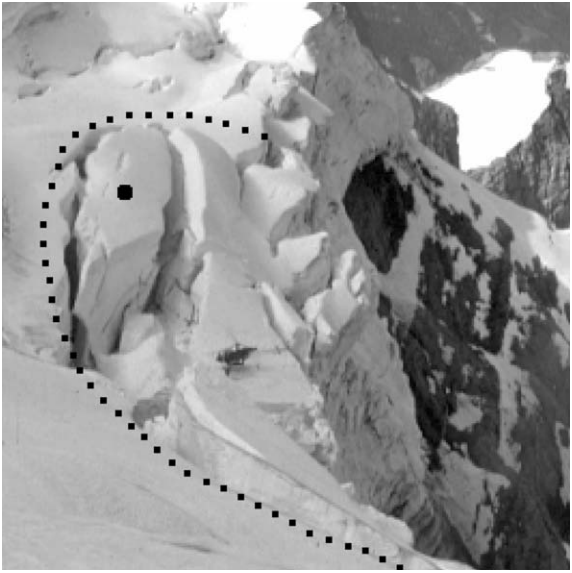

>V roce 1999 se začal vysoko v horách nad Grindelwaldem ve Švýcarsku pohybovat
zavěšený ledovec a ohrožoval oblast pod sebou obrovským vodopádem z ledu. Aby se
zabránilo vážné nehodě, bylo nutné přesně předpovědět, kdy se ledovec utrhne. Vědci z ETH v Zürichu (M. Funk) tedy usadili do masy ledu měřicí tyč (viz obrázek) a pozorně sledovali měnící se umístění tyče. Změřené údaje jsou
>
>
| Čas měření $t$ (dny) | Pohyb tyče $s(t)$ (metry) |
|:--------:| -------- |
| $t_0=0$ | $s_0 = 0$ |
| $t_1=2$ | $s_1 = 0.529$ |
| $t_2=7$ | $s_2 = 1.936$ |
| $t_3=12$ | $s_3 = 3.598$ |
| $t_4=13$ | $s_4 = 3.977$ |
| $t_5=15$ | $s_5 = 4.802$ |
| $t_6=16$ | $s_6 = 5.219$ |
| $t_7=17$ | $s_7 = 5.667$ |
| $t_8=19$ | $s_8 = 6.669$ |
| $t_9=20$ | $s_9 = 7.208$ |
| $t_{10}=22$ | $s_{10} = 8.464$ |
>
>Čas t = 0 odpovídá 18. červenci 1999, 7. hodině ráno. Dřívější zkušenosti s ledovcovými vodopády (zejména s ledopádem na Weisshornu)
ukázaly, že zvyšující se rychlost podobných ledových mas vyhovuje vzorci
>
>\begin{equation*} v(t) = v_0 + \frac{a_0}{(t_{\infty}-t)^{n}}, \end{equation*}
>
>neboli (po integraci)
>
>\begin{equation*} s(t) = s_0 + v_0\cdot t - a_0 \cdot \frac{ (t_{\infty}-t)^{1-n} - t_{\infty}^{1-n} }{n-1}, \end{equation*}
>
> kde $t_{\infty}>0$ odpovídá času utržení ledovce. Naším cílem je na základě 11 dostupných měření určit ***parametry modelu*** $s_0,v_0,a_0,t_{\infty}$ a $n$ tak, aby odpovídaly měřením a tudíž předpovědět čas utržení ledovce. Z předchozích modelů víme, že $n\approx \tfrac{1}{2}$.

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír & kódění**

- **Tužka a papír**: Rozepište formulaci výše jako problém [(3)](#eq3) pro konkrétní $\mathbf{F}$ a interpretujte $\mathbf{x}$.

- **Kódění**: Nastudujte si a použijte funkci [`scipy.optimize.curve_fit()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html#scipy.optimize.curve_fit) pro výpočet našich neznámých parametrů.
  - My si vystačíme s "unconstrained optimization", ale je zapotřebí použít rozumný počáteční odhad - využijte, že máme pro některé neznámé parametry odhady (např. $n\approx 0.5$ nebo $t_{\infty} > 22$) a naopak volíme odhad $0$ pro hodnoty u kterých nemáme žádný odhad.
  - Zřejmě bude nutné implementovat funkci `glacier_motion()`, která odpovídá funkci $s(t)$ výše.
  - Jakou minimalizační metodu tato pythonová implementace používá?
  - Pro konvergenci algoritmu (aspoň v mém set-upu) je zapotřebí zvýšit počet iterací - mně stačilo `maxfev = 10000`.

- Vykreslete data $(t_i,s_i)_{i=0,\dotsc ,10}$ spolu s predikcemi modelu `t_pred, s_pred`, kde `s_pred = glacier_motion(t_pred, ... optimalni parametry ...)` a `t_pred` jsou body nagenerované na intervalu $(0,t_{\infty})$, např. pomocí `t_pred = np.linspace(0,t_infty,100)`.

- Ledovec se utrhl 14. srpna ve dvě hodiny ráno. Jak realita koresponduje s vaší předpovědí?

</blockquote>
</div>

**Pohyb ledovce - fit modelu:**

In [ ]:
def glacier_motion(t, s0, v0, a0, t_infty, n):
    """s(t) pro pohyb ledovce (vzorec ze zadani vyse)."""
    ...

t = np.array([0, 2., 7., 12., 13., 15., 16., 17., 19., 20., 22.])
s = np.array([0, 0.529, 1.936, 3.598, 3.977, 4.802, 5.219, 5.667, 6.669, 7.208, 8.464])

# Vas kod: pouzijte curve_fit() s rozumnym pocatecnim odhadem p0 a dostatecnym maxfev
popt, pcov = ...
t_pred = ...
s_pred = ...

plt.plot(t_pred, s_pred, label="predpoved")
plt.plot(t, s, 'o', markeredgecolor='k', label="mereni")
plt.xlabel("cas (dny)"); plt.ylabel("pohyb ledovce (metry)"); plt.legend(); plt.show()

## Část B - Ortogonální polynomy

---
- [poznámky z přednášky - ortogonální polynomy](https://www.karlin.mff.cuni.cz/~kucera/ZNM/4%20-%20Ortogonalni%20polynomy.pdf)
- další materiály:
  - částečně dostupná (a hodně pokročilá) kniha [Trefethen: Approximation Theory and Approximation Practice](https://www.chebfun.org/ATAP/atap-first6chapters.pdf) (Kapitoly 2 a 3)

- ***Primární úlohy*** : B1

- ***Úlohy k bonusové části zkoušky*** : B1

- základní ***Learning outcomes*** (cviko, nikoliv přednáška)
  - Umím definovat ortogonalitu polynomů.
  - Umím transformovat ortogonální polynomy na intervalu $(a,b)$ na ortogonální polynomy na intervalu $(c,d)$.
  - Umím charakterizovat Chebyshevovy polynomy pomocí min-max vlastnosti.
---

### Intro

Velkou část první půlky semestru jsme strávili příklady z numerické lineární algebry, které mimo jiné ilustrovaly důležitost ***ortogonálních/ortonormálních transformací*** - pro numerické výpočty se ukázaly naprosto klíčové.

Jedna přirozená navazující otázka je:
> "Ano, v lingebře to je vcelku přímočaré, ale co nám to říká o tom, jak počítat s funkcemi/integrály?"

Jedna z možných odpovědí je následující (a má dvě části):

- Musíme pracovat s funkcemi v kontextu vektorových prostorů (takové příklady jste již na lingebře viděli a na teorii míry přibydou další).

- Pro řešení úloh s funkcemi je pak nutné/vhodné používat podobné algoritmy jako v lineární algebře a vyvarovat se výpočtům se špatně podmíněnými transformacemi a/nebo ve špatně podmíněných bázích.


Tuto ideu hlouběji rozpracovává [NMMA331: Úvod do funkcionální analýzy](https://is.cuni.cz/studium/predmety/index.php?do=predmet&kod=NMMA331) nebo [NMMA204: Matematická analýza 4](https://is.cuni.cz/studium/predmety/index.php?do=predmet&kod=NMMA204), které vás čekají v dalším průběhu studia a tvoří naprosto fundamentální základ/rámec pro mnoho, ne-li většinu moderních výpočtů.

V tomhle kurzu uvidíme v následujících dvou týdnech, že jeden takový vhodný postup pro manipulaci s funkcemi je tzv. ***Lagrangeova interpolace v Chebyshevových/Legendrových bodech***. Takže na tomhle cviku se podíváme co jsou ty Chebyshevovy a Legendrovy body zač.

Začneme tím, že si vezmeme vektorový prostor polynomiálních funkcí, tj.

\begin{equation*}
\mathcal{P}_n = \{ \, p(x) : [a,b] \rightarrow \mathbb{R} \, |\; p \; \mathrm{je\, monicky \, polynom} \; \; \& \; \; \mathrm{deg}(p)\leq n \,\}
\quad \mathrm{a}\quad
\mathcal{P} = \{ \, p(x) : [a,b] \rightarrow \mathbb{R} \, |\; p \; \mathrm{je\, monicky \, polynom} \,\}
\end{equation*}

a opatříme ho skalárním součinem $(\cdot, \cdot )_{w}$ definovaným jako

\begin{equation*} (p,q)_{w} := \int_a^b p(x)q(x) \cdot w(x) \mathrm{d}x, \end{equation*}

kde $w(x) : (a,b) \rightarrow \mathbb{R}$ je nezáporná, integrovatelná funkce s konečnou variací (v takovém případě integrál výše odpovídá [Riemann-Stieltjesovu integrálu](https://en.wikipedia.org/wiki/Riemann-Stieltjes%integral)). Vůči tomuto skalárnímu součinu pak zjevně můžeme konstruovat ortogonální/ortonormální bazi prostoru $\mathcal{P}_n$ pro libovolné $n$ a tedy i prostoru $\mathcal{P}$.

V praxi je důležitých několik konkrétních set-upů - my si z nich zmíníme dva konkrétní:

- [Chebyshevovy polynomy](https://en.wikipedia.org/wiki/Chebyshev_polynomials#) odpovídající $w(x):= 1/\sqrt{1-x^2}$ & $[a,b] = [-1,1]$,
  - na přednášce definované jako $T_n(x) := \cos \left( n \arccos (x) \right)$ pro libovolné $n\in \mathbb{N}$.
  - *monické* Chebyshevovy polynomy značíme $\tilde{T}_n$ a můžeme je charakterizovat/definovat skrze
  \begin{equation*}\mathrm{arg}\min\limits_{q_n \in \mathcal{P}_n} \, \max\limits_{x\in [-1,1]} \, |q_n(x)| = \tilde{T}_n(x),
  \quad \& \quad
  \min\limits_{q_n \in \mathcal{P}_n} \, \max\limits_{x\in [-1,1]} \, |q_n(x)| = \max\limits_{x\in [-1,1]} \, |\tilde{T}_n(x)|  = \frac{1}{2^{n-1}}.
  \end{equation*}
  - **Poznámka:** ve skutečnosti existuje několik typů Chebyshevových polynomů - Chebyshevovy polynomy 1., 2. a 3. druhu, viz [wiki](https://en.wikipedia.org/wiki/Chebyshev_polynomials).

- [Legendrovy polynomy $P_n(x)$](https://en.wikipedia.org/wiki/Legendre_polynomials) odpovídající $w(x):= 1$ & $[a,b] = [-1,1]$.

**Definice pro obecný interval** $[a,b]$:
  - vezmeme si lineární transformaci $t(x) = \alpha x + \beta$, která zobrazí $[a,b]$ na $[-1,1]$ a zároveň zobrazí krajní body na krajní body, tedy
  \begin{equation*}
  t \, : \, [a,b] \rightarrow [-1,1] \quad \mathrm{a} \quad t(a)=-1 \; \& \; t(b)=1
  \end{equation*}
  a označíme si novou proměnnou jako $\xi := t(x) \in [-1,1]$.
  - $n$-tý monický Chebyshevův polynom na $[a,b]$ označíme jako $\hat{T}_n(x)$ a definujeme ho jako
  \begin{equation*} \hat{T}_n := \tilde{T}_n \circ t \quad \mathrm{tj.}\quad \hat{T}_n(x) := \tilde{T}_n(t(x)). \end{equation*}

  - $n$-tý monický Legendrův polynom na $[a,b]$ označíme jako $\hat{P}_n(x)$ a definujeme ho jako
  \begin{equation*} \hat{P}_n := \tilde{P}_n \circ t \quad \mathrm{tj.}\quad \hat{P}_n(x) := \tilde{P}_n(t(x)). \end{equation*}

### Úloha B1 - Chebyshevovy polynomy

Na přednášce jsme si zadefinovali Chebyshevovy polynomy 1. druhu jako

\begin{equation*} T_n(x) := \cos \left( n \arccos (x) \right) .\end{equation*}

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

- Ukažte, že funkce $T_n$ (a tedy i $\tilde{T}_n$) jsou opravdu polynomy stupně právě $n$.

- Ukažte, že kořeny $T_n$ jsou dány jako
  \begin{equation*} x_k=\cos\left(\dfrac{\left( 2k-1\right)\pi}{2n}\right), \quad k=1,\ldots,n.\end{equation*}
  a extrémy (minima a maxima) jsou dány jako
  \begin{equation*} x_k=\cos\left(\dfrac{k\pi}{n}\right), \quad k=0,\ldots,n. \end{equation*}

- [Nápověda & hinty](#head-w09-hinty-b1)

</blockquote>
</div>

### Úloha B2 - transformace OG polynomů

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Vezmeme si obecný konečný interval $[a,b]$.
- Najděte afiní transformaci $t \, : \, [a,b] \rightarrow [-1,1]$, která zobrazí krajní body na krajní body, tj. $t(a)=-1$ \& $t(b)=1$.
- Ukažte, že funkce $\hat{T}_n,\hat{P}_n$ definované výše jsou polynomy.
- Najděte funkce $w_{\mathrm{Leg}}$ a $w_{\mathrm{Cheb}}$, vůči kterým jsou Legendrovy a Chebyshevovy polynomy na $[a,b]$ definované výše ortogonální.

- [Nápověda & hinty](#head-w09-hinty-b2)

</blockquote>
</div>

### ZÚ - zachovávání min-max vlastností

<div style="border-left: 4px solid #0969da; background-color: #ddf4ff; padding: 0.75em 1em; border-radius: 4px; margin: 1em 0;">
<blockquote style="margin: 0; padding: 0; border: none;">

**📝 Tužka a papír**

Ukažte, že monické Chebyshevovy polynomy na $[a,b]$ lze charakterizovat analogicky jako výše.

- Najděte $\alpha_n > 0$ takové, že $\alpha_n \hat{T}_n(x)$ je monický polynom.
- Ukažte, že platí

\begin{equation*}
\mathrm{arg}\min\limits_{q_n \in \mathcal{P}_n} \, \max\limits_{x\in [a,b]} \, |q_n(x)| = \alpha_n\hat{T}_n(x).
\end{equation*}

- Vypočítejte

\begin{equation*}
\min\limits_{q_n \in \mathcal{P}_n} \, \max\limits_{x\in [a,b]} \, |q_n(x)| = \max\limits_{x\in [a,b]} \, |\hat{T}_n(x)| .
\end{equation*}

- [Nápověda & hinty](#head-w09-hinty-zu-b)

</blockquote>
</div>

### Ilustrace

Monické polynomy stupně $n$ s kořeny $x_1,\dotsc ,x_n \in \mathbb{R}$ můžeme zapsat jako
<a name="eq4"></a>
\begin{equation*}
\tag{4}
q_n(x) = (x-x_1)\cdot \dotsc \cdot (x-x_n).
\end{equation*}
Ortogonální polynomy (jako třeba Legendrovy nebo Chebyshevovy) mají všechny kořeny reálné, takže je opravdu můžeme zapsat v součinovém tvaru výše. Níže jsou vykreslené 3 typy monických polynomů tvaru [(4)](#eq4):
  - $x_1,\dotsc ,x_n$ bereme jako kořeny $n$-tého Chebyshevova polynomu na $[-1,1]$ (a tedy $q_n(x) = (x-x_1)\cdot \dotsc \cdot (x-x_n) = \tilde{T}_n(x)$),
  - $x_1,\dotsc ,x_n$ bereme jako kořeny $n$-tého Legendrova polynomu na $[-1,1]$ (a tedy $q_n(x) = (x-x_1)\cdot \dotsc \cdot (x-x_n) = \tilde{P}_n(x)$),
  - $x_1,\dotsc ,x_n$ bereme jako ekvidistantní body na $[-1,1]$ (analogické Wilkinsonovu polynomu),

In [ ]:
from scipy.special import roots_chebyt, roots_legendre
from numpy.polynomial.polynomial import polyvalfromroots


a = -1
b = 1
n_to_try = [3, 4, 7]
colors_list = ["tab:blue", "orange", "tab:green"]
x_eval = np.linspace(a, b, 1000)
fig, [[ax1, ax2, ax3], [ax4, ax5, ax6], [ax7, ax8, ax9]] = plt.subplots(nrows=3, ncols=3, figsize=(22, 11), gridspec_kw={'hspace': 0.35, 'wspace': 0.3})

for ind in range(0, len(n_to_try)):
    n = n_to_try[ind]
    x_equi = np.linspace(a, b, n)
    x_cheb = roots_chebyt(n)[0]
    x_leg = roots_legendre(n)[0]

    ### equi
    ax1.set_title("Ekvidistantni body")
    ax1.plot(x_equi, np.ones(len(x_equi))*(-ind), label="n = {}".format(n), c=colors_list[ind], lw=0, marker="o", alpha=.6, ms=7, markeredgecolor="k"); ax3.set_yticklabels([])

    if ind == 0:
        ax4.set_title(r"polynom $(x-x_0)\cdot \dots \cdot (x-x_n), n =$ {}".format(n_to_try[ind]))
        ax4.plot(x_equi, np.zeros(len(x_equi)), lw=0, marker="o", c=colors_list[ind], alpha=.6, ms=7, markeredgecolor="k")
        ax4.plot(x_eval, polyvalfromroots(x_eval, x_equi), ':', c=colors_list[ind], label="n = {}".format(n), lw=1)

    ax7.set_title(r"polynom $(x-x_0)\cdot \dots \cdot (x-x_n)$")
    ax7.plot(x_equi, np.zeros(len(x_equi)), lw=0, marker="o", c=colors_list[ind], alpha=.6, ms=7, markeredgecolor="k")
    ax7.plot(x_eval, polyvalfromroots(x_eval, x_equi), ':', c=colors_list[ind], label="n = {}".format(n), lw=1)

    ### leg
    ax2.set_title("Legendrovy body")
    ax2.plot(x_leg, np.ones(len(x_leg))*(-ind), label="n = {}".format(n), lw=0, c=colors_list[ind], marker="o", alpha=.6, ms=7, markeredgecolor="k"); ax2.set_yticklabels([])
    ax2.legend(loc='upper center', bbox_to_anchor=(0.5, 1.35), fancybox=True, shadow=True, ncol=5)

    if ind == 0:
        ax5.set_title(r"polynom $(x-x_0)\cdot \dots \cdot (x-x_n), n =$ {}".format(n_to_try[ind]))
        ax5.plot(x_leg, np.zeros(len(x_leg)), lw=0, marker="o", c=colors_list[ind], alpha=.6, ms=7, markeredgecolor="k")
        ax5.plot(x_eval, polyvalfromroots(x_eval, x_leg), ':', c=colors_list[ind], label="n = {}".format(n), lw=1)

    ax8.set_title(r"polynom $(x-x_0)\cdot \dots \cdot (x-x_n)$")
    ax8.plot(x_leg, np.zeros(len(x_leg)), lw=0, marker="o", c=colors_list[ind], alpha=.6, ms=7, markeredgecolor="k")
    ax8.plot(x_eval, polyvalfromroots(x_eval, x_leg), ':', c=colors_list[ind], label="n = {}".format(n), lw=1)

    ### cheb
    ax3.set_title("Chebyshevovy body")
    ax3.plot(x_cheb, np.ones(len(x_cheb))*(-ind), label="n = {}".format(n), c=colors_list[ind], lw=0, marker="o", alpha=.6, ms=7, markeredgecolor="k"); ax1.set_yticklabels([])

    if ind == 0:
        ax6.set_title(r"polynom $(x-x_0)\cdot \dots \cdot (x-x_n), n =$ {}".format(n_to_try[ind]))
        ax6.plot(x_cheb, np.zeros(len(x_cheb)), lw=0, c=colors_list[ind], marker="o", alpha=.6, ms=7, markeredgecolor="k")
        ax6.plot(x_eval, polyvalfromroots(x_eval, x_cheb), ':', c=colors_list[ind], label="n = {}".format(n), lw=1)

    ax9.set_title(r"polynom $(x-x_0)\cdot \dots \cdot (x-x_n)$")
    ax9.plot(x_cheb, np.zeros(len(x_cheb)), lw=0, c=colors_list[ind], marker="o", alpha=.6, ms=7, markeredgecolor="k")
    ax9.plot(x_eval, polyvalfromroots(x_eval, x_cheb), ':', c=colors_list[ind], label="n = {}".format(n), lw=1)

plt.show()

## Hinty

<a name="head-w09-hinty-zu"></a>
### Hinty ZU

#### Hint "taylor"

Jinými slovy, zanedbáme všechny členy obsahující $f^{(2)}(x), f^{(3)}(x)$ atd., čímž získáme $f^{(1)}(x) \approx$ ...pouze výrazy obsahující $f(x),f(x+h)$.

<a name="head-w09-hinty-a1"></a>
### Hinty A1

#### Ukázka syntaxe "lambda"

Skalární funkci pro line search si můžeme zadefinovat uvnitř každé z našich implementací pomocí existující funkce `f`, keyword `lambda` a matematických formulací výše. Konkrétní příklady na používání:

  Příklad 1 - definujeme si funkci $f(x) := x^2 - 17$.
  ```
  f = lambda x: x**2 - 17
  print(f(5))  ### vytiskne 5**2-17, tj. 8
  ```

  Příklad 2 - definujeme si funkci $g(\alpha) := f(\alpha + 3)$.
  ```
  g = lambda x: f(x+3)
  print(g(5))  ### vytiskne (5+3)**2-17, tj. 47
  ```

  Příklad 3 - definujeme si funkci $h(\beta) := g(\beta - 3)$.
  ```
  h = lambda x: g(x-3)
  print(h(5))  ### vytiskne (5+3-3)**2-17, tj. 8
  ```

#### Hint "implementace"

Pro 1D minimalizaci libovolné funkce použijte [`minimize_scalar(f_line_search, tol=tol)`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html) z knihovny `scipy.optimize`, která nalezne minimum s přesností/tolerancí `tol`. Pozor na to, že output této funkce je sám o sobě python objekt - hodnotu inputu, který danou funkci minimalizuje získáme například následujícím způsobem.
  ```
  f = lambda x: x**2 - 1  # funkce co chci minimalizovat
  minimize_result = minimize_scalar(f, tol=tol)  # pustim minimalizaci, output je objekt
  x_min = minimize_result.x  # vytahnu si z toho objektu ten input co minimalizuje "f"
  ####################
  print(x_min)  # vytiskne minimalizujici input, tj. x=0
  print(minimize_result)  # vytiskne info o minimalizaci, nejen x=0, ale taky tu minimalni hodnotu,
                           # pocet vyhodnoceni funkce "f", atd.
  ```

<a name="head-w09-hinty-b1"></a>
### Hinty B1

#### Hint "idea"

Odvoďte rekurentní vztah pro výpočet Chebyshevova polynomu $T_{n+1}(x)$ na základě $T_{n}(x)$ a $T_{n-1}(x)$.

#### Hint "vzoreček"

Zopakujte si [součtové vzorce](https://en.wikipedia.org/wiki/Trigonometric_functions#Sum_and_difference_formulas) pro $\cos()$ součtu a rozdílu dvou argumentů.

<a name="head-w09-hinty-b2"></a>
### Hinty B2

#### Hint "idea"

Vše lze převést na manipulaci s Legendrovými/Chebyshevovými polynomy na $[-1,1]$, kde máme teorii z přednášky shrnutou výše, o kterou se můžeme opřít.

<a name="head-w09-hinty-zu-b"></a>
### Hinty ZU-B

#### Hint "škálování"

Monické polynomy jsou obecně tvaru $x^n + \sum\limits_{i=0}^{n-1} \gamma_i x^i$. Pokud máme polynom tvaru $(\alpha x + \beta)^n + \sum\limits_{i=0}^{n-1} \gamma_i (\alpha x + \beta)^i$, jaký je koeficient u jeho vedoucího členu, tj. u $x^n$? Jak můžeme přepsat tento polynom na $C \cdot q_n(x)$ pro nějaký monický polynom $q_n$? Použijte znalosti z přednášky.